*This homework focuses on the seismic station POHA (network code IU), and the following channels:*

1. Channel BHZ, location 00
2. Channel BHZ, location 10
3. Channel HNZ, location 20

*Firstly, we will focus on this event: https://en.wikipedia.org/wiki/2018_Hawaii_earthquake*

****

*(a) What are this event’s magnitude and the UTCDateTime for this event’s origin time? What is the
approximate distance between the epicenter and the station POHA?*

La magnitud del evento según la escala de magnitud de momento fue de 6.9 Mw y la hora de origen del evento fue 2018-05-04 22:32:55 UTC.

La ubicación del epicentro según la USGS fue en 19.318°N, 154.999°W y la ubicación de la estación POHA está en 19.757°N, 155.533°W.

Usando una función de la librería ObsPy (gps2dist_azimuth), la cual calcula la distancia geodésica sobre el elipsoide de referencia WGS84 a partir de las coordenadas geográficas (latitud y longitud) de ambos puntos, obteniendo la distancia en metros (junto con el acimut y contra-acimut).

Al aplicar esto tal como se muestra en el siguiente bloque de código nos entrega una distancia entre el epicentro del terremoto y la estación POHA de aproximadamente 74.18 [km].

Al comparar este resultado con el registrado en https://earthquake.usgs.gov/earthquakes/eventpage/hv70116556/origin/phase, notamos que nos muestra una distancia de 0.67°, lo que equivale a 74.50 [km] tal como también se muestra en el código.

In [11]:
import obspy

d_yo = obspy.geodetics.gps2dist_azimuth(lat1=19.318, lon1=-154.999, lat2=19.757, lon2=-155.533)
print(f"Distancia geodésica: {d_yo[0] / 1000:.2f} km")

d_usgs = obspy.geodetics.degrees2kilometers(0.67)
print(f"Distancia USGS (0.67°): {d_usgs:.2f} km")

Distancia geodésica: 74.18 km
Distancia USGS (0.67°): 74.50 km


****

*(b) Use client.get stations for the station POHA to obtain the location codes (cha.location code), channel
codes (cha.code), sample rates (cha.sample rate), instrument depths (cha.depth) and sensors (cha.sensor)
for these three channels recording at this time. Why are there two BHZ channels located at different
depths?*

In [30]:
from obspy import UTCDateTime
from obspy.clients.fdsn import Client

client = Client("IRIS")

t_i = UTCDateTime("2018-05-04T22:32:55")
t_f = t_i + 600  # 10 minutos (600 segundos)

inv = client.get_stations(
    network="IU",
    station="POHA",
    location="00,10,20",
    channel="BHZ,HNZ",
    starttime=t_i,
    endtime=t_f,
    level="response", 
)

print(inv) # Es como una jerarquía? Networks --> Stations --> Channels --> Data?  Entonces debemos iterar sobre este objeto...

print("\n")
# Ahora queremos recorrer cada canal de la estación para obtener la información de cada uno.

for network in inv:
    for station in network:
        for channel in station:
            print(f" Location: {channel.location_code} | Channel: {channel.code}")
            print(f" Sample rate: {channel.sample_rate} Hz")
            print(f" Depth: {channel.depth} m")
            print(f" Sensor: {channel.sensor.description} | Type: {channel.sensor.type}")
            print("-"*45)

c:\Users\Kaito\miniconda3\envs\sismologia\lib\site-packages\obspy\clients\fdsn\client.py:257: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)


Inventory created at 2026-11-20T17:29:47.610700Z
	Created by: EarthScope WEB SERVICE: fdsnws-station | version: 1.1.61
		    https://service.earthscope.org/fdsnws/station/1/query?starttime=201...
	Sending institution: EarthScope (EarthScope)
	Contains:
		Networks (1):
			IU
		Stations (1):
			IU.POHA (Pohakuloa, Hawaii, USA)
		Channels (3):
			IU.POHA.00.BHZ, IU.POHA.10.BHZ, IU.POHA.20.HNZ


 Location: 00 | Channel: BHZ
 Sample rate: 20.0 Hz
 Depth: 80.0 m
 Sensor: Velocity Sensor | Type: GEOTECH
---------------------------------------------
 Location: 10 | Channel: BHZ
 Sample rate: 40.0 Hz
 Depth: 0.0 m
 Sensor: Velocity Sensor | Type: STRECKEISEN
---------------------------------------------
 Location: 20 | Channel: HNZ
 Sample rate: 100.0 Hz
 Depth: 0.0 m
 Sensor: Accelerometer | Type: KINEMETRICS
---------------------------------------------


Una vez obtenido todos los detalles acerca de cada canal vertical de la estación POHA notamos que tenemos dos canales BHZ y HNZ en superficie registrando a 40 y 100 HZ respectivamente. Además de otro canal BHZ ubicado a 80 metros de profundidad registrando a 20 Hz. Los canales BHZ usan sensores de velocidad para registrar sus valores (notar que no son el mismo tipo de sensor), mientras que los HNZ usan acelerómetros para esto, es decir, debemos tener cuidado con la transformación al SI ya que no son las mismas unidades (m/s vs m/s^2).

Por otro lado, al usar frecuencias más altas (40 Hz y 100 Hz) (periodos cortos) podemos observar señales de alta frecuencia típicas de eventos en el campo cercano (conservan gran parte de su energía aún producto de la poca atenuación), mientras que tasas de muestreo con frecuencias más bajas (20 Hz) es suficiente para capturar ondas de mayor periodo asociados principalmente a eventos más distantes (telesismos). La idea de colocar un segundo sensor para el canal BHZ a unos 80 metros de profundidad nace de querer registrar señales más "puras" que no estén muy distorsionadas por las señales de ruido que se registran en la superficie y en los primeros metros de profundidad. Además de tener un sensor de respaldo (la de la superficie) en caso de que esta estación bajo tierra falle y no registre los datos, tengamos el 2do sensor en la superficie cubriendo la pérdida de los datos y dando fidelidad a lo registrado.

****

*(c) Use client.get waveforms to obtain the waveforms for these three channels, starting from the event
origin time and continuing for 10 minutes. Plot the waveforms of these three channels.*

c:\Users\Kaito\miniconda3\envs\sismologia\lib\site-packages\obspy\clients\fdsn\client.py:257: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)


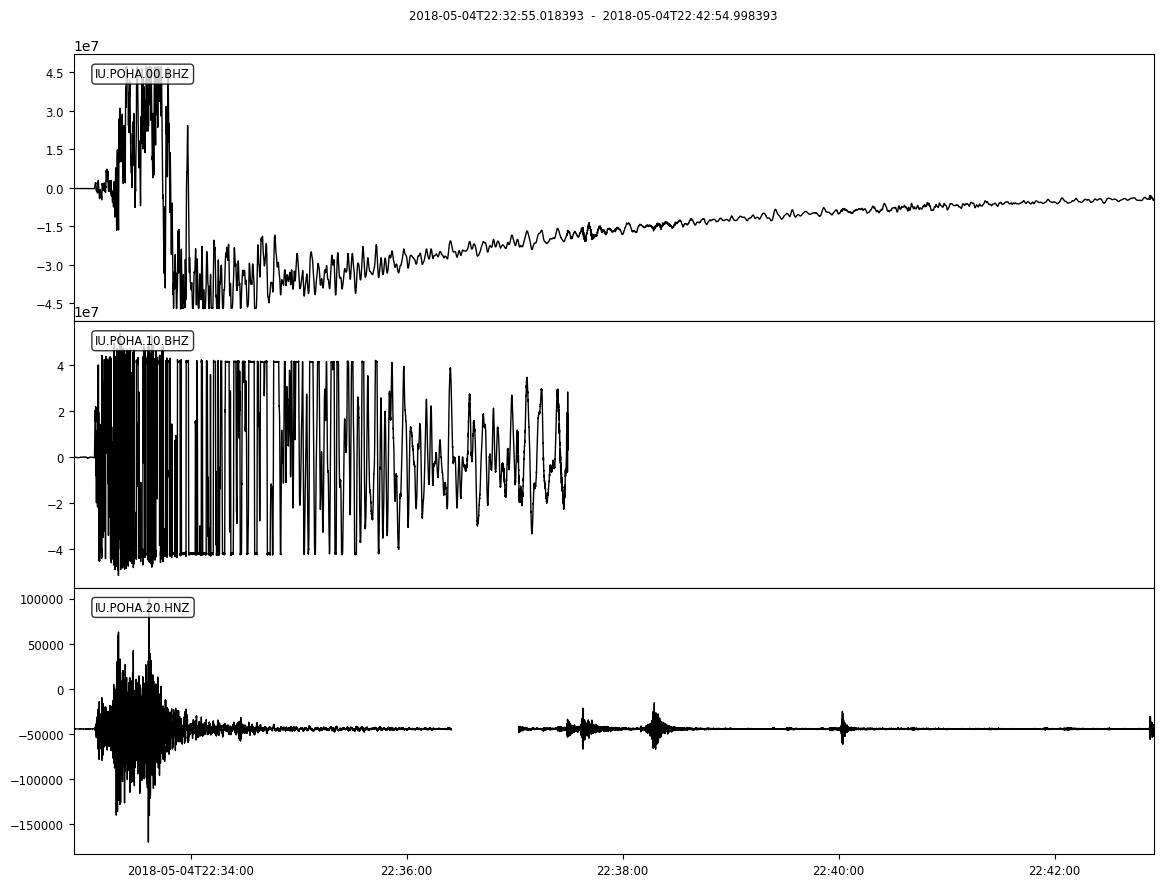

In [16]:
from obspy import UTCDateTime
from obspy.clients.fdsn import Client

client = Client("IRIS")

t_i = UTCDateTime("2018-05-04T22:32:55")
t_f = t_i + 600  # 10 minutos (600 segundos)

st = client.get_waveforms(
    network="IU",
    station="POHA",
    location="00,10,20",
    channel="BHZ,HNZ",
    starttime=t_i,
    endtime=t_f,
)

out1 = st.plot(equal_scale=False, size=(1200, 900), number_of_ticks=5, show_y_UTC_label=True)
out1.savefig("waveforms_tarea1.png", dpi=600)

Una vez obtenidas las formas de la onda para cada canal, teniendo la representación para el canal BHZ a 80 metros de profundidad, BHZ en la superficie de la estación y HNZ igualmente en la superficie respectivamente. Notamos en el primer canal una variación instantánea de un máximo a un mínimo teniendo en ambos extremos señales de saturación producto de la magnitud de la energía de la onda recibida y el hecho de estar en el campo cercano entre la fuente y la estación, además de una posterior recentralización de la masa al haberse saturado producto del terremto. En el segundo canal (BHZ superficie) notamos un efecto de saturación muy agresivo desde el inicio de la onda P registrada que se extiende por casi toda la duración del evento registrado hasta que finalmente el equipo deja de registrar datos, estos datos, al igual que los anteriores terminan siendo 0 útiles producto de la saturación que registran que ya hacen que no reflejen el verdadero movimiento de la onda incidente en el equipo. Finalmente, con el canal HNZ, notamos que durante la duración del primer evento principal se registran al menos 3 tipos de ondas, correspondientes a la onda P (la primera que llega), la onda S (primer registro de gran amplitud) y posteriormente la onda de superficie que provoca el tercer peak en el registro. Además se registran al menos 5 réplicas posterior al evento con una amplitud menor al evento y un corte en el tiempo de registro de al menos ~30 segundos.

****

*(d) Use the instrument responses of these channels to convert the waveform data to units of acceleration and estimate the maximum accelerations recorded on these channels as a % of g.*

Primero, a modo de comentario antes de empezar con el código, anteriormente se mencionó que los canales BHZ a distintas profundidades miden velocidad (m/s) y lo registran en cuentas digitales, mientras que el canal HNZ mide aceleración (m/s^2) y registra esto en cuentas digitales también. Sin embargo al usar los polos y ceros obtenidos a través de Wilber3, estos transforman las cuentas digitales a metros [m] por lo que los datos de cada sensor que registró el evento se deben diferenciar dos veces sin importar si era un sensor de velocidad o un acelerómetro para poder obtener aceleración [m/s^2] para cada caso.

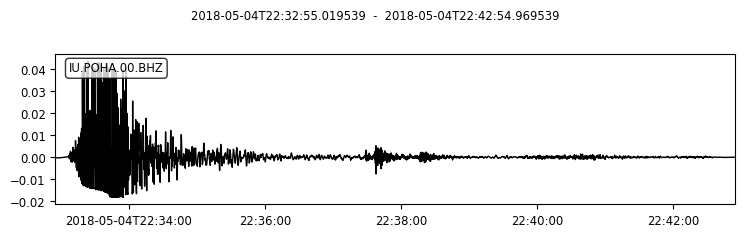

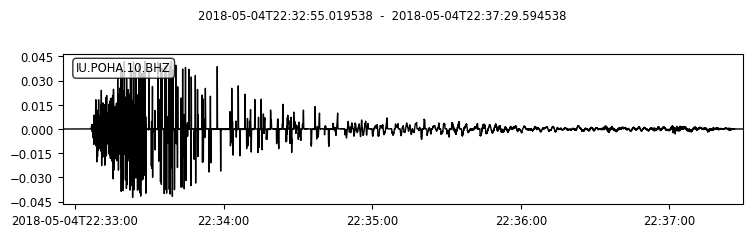

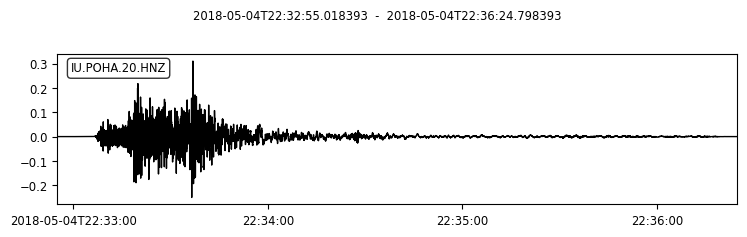

In [2]:
from obspy.io.sac.sacpz import attach_paz
tr_00 = st.select(location="00")[0]
paz_file00 = "SACPZ.IU.POHA.00.BHZ"
tr_00n = tr_00.copy()
attach_paz(tr_00n, paz_file=paz_file00)
paz_00 = tr_00n.stats.paz

tr_00n.detrend(type="demean")
tr_00n.detrend(type="linear")
tr_00n.taper(max_percentage=0.05, type="cosine")

tr_00n.simulate(paz_remove=paz_00, pre_filt=(0.001, 0.01, 8, 10)).differentiate().differentiate()
tr_00g = tr_00n.copy()
#tr_00g.data = (tr_00n.data / 9.81) * 100  # Convertir a %g
out_t0 = tr_00g.plot()
out_t0.savefig("traza_loc00_acc_tarea1")


tr_10 = st.select(location="10")[0]
paz_file10 = "SACPZ.IU.POHA.10.BHZ"
tr_10n = tr_10.copy()
attach_paz(tr_10n, paz_file=paz_file10)
paz_10 = tr_10n.stats.paz

tr_10n.detrend(type="demean")
tr_10n.detrend(type="linear")
tr_10n.taper(max_percentage=0.05, type="cosine")
tr_10n.simulate(paz_remove=paz_10, pre_filt=(0.001, 0.01, 15, 20)).differentiate().differentiate()
tr_10g = tr_10n.copy()
#tr_10g.data = (tr_10n.data / 9.81) * 100  # Convertir a %g
out_t1 = tr_10g.plot()
out_t1.savefig("traza_loc10_acc_tarea1")


tr_20 = st.select(location="20")[0]
paz_file20 = "SACPZ.IU.POHA.20.HNZ"
tr_20n = tr_20.copy()
attach_paz(tr_20n, paz_file=paz_file20)
paz_20 = tr_20n.stats.paz

tr_20n.detrend(type="demean")
tr_20n.detrend(type="linear")
tr_20n.taper(max_percentage=0.05, type="cosine")
tr_20n.simulate(paz_remove=paz_20, pre_filt=(0.001, 0.01, 40, 50)).differentiate().differentiate()
tr_20g = tr_20n.copy()
#tr_20g.data = (tr_20n.data / 9.81) * 100  # Convertir a %g
out_t2 = tr_20g.plot()
out_t2.savefig("traza_loc20_acc_tarea1")


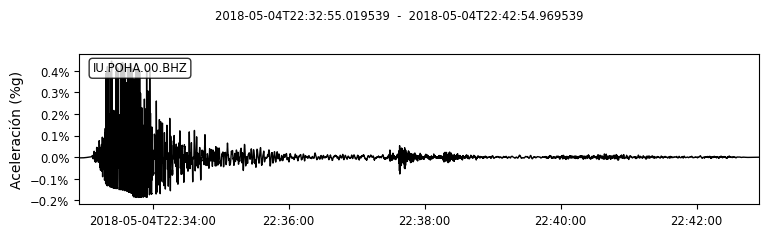

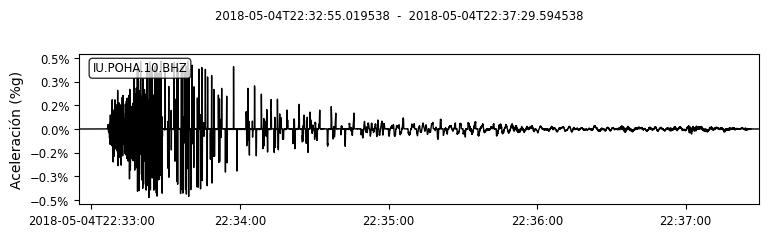

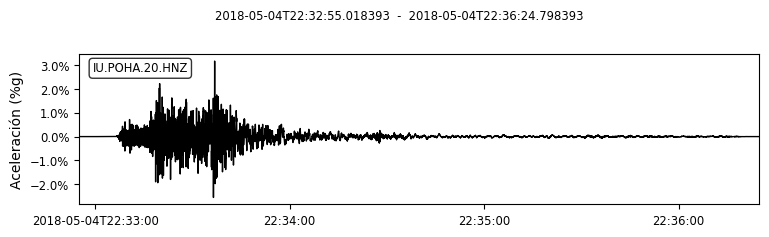

In [3]:
import matplotlib.ticker as mtick
import numpy as np

tr_00g.data = (tr_00n.data / 9.81) * 100  # Convertir a %g
out_t0 = tr_00g.plot(show=False)

ax0 = out_t0.axes[0]
ax0.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax0.set_ylabel("Aceleración (%g)")

out_t0.savefig("traza_loc00_pg_tarea1")
display(out_t0)


tr_10g.data = (tr_10n.data / 9.81) * 100  # Convertir a %g
out_t1 = tr_10g.plot(show=False)

ax1 = out_t1.axes[0]
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax1.set_ylabel("Aceleración (%g)")

out_t1.savefig("traza_loc10_pg_tarea1")
display(out_t1)


tr_20g.data = (tr_20n.data / 9.81) * 100  # Convertir a %g
out_t2 = tr_20g.plot(show=False)

ax2 = out_t2.axes[0]
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax2.set_ylabel("Aceleración (%g)")

out_t2.savefig("traza_loc20_pg_tarea1")
display(out_t2)

In [4]:
# Estimar aceleraciones máximas como un porcentaje de g
import numpy as np

amax0 = np.abs(np.max(tr_00g.data))
print(f"Aceleración máxima registrada como %g para BHZ en el pozo es: {amax0:.2f}%")

amax1 = np.abs(np.max(tr_10g.data))
print(f"Aceleración máxima registrada como %g para BHZ en superficie es: {amax1:.2f}%")

amax2 = np.abs(np.max(tr_20g.data))
print(f"Aceleración máxima registrada como %g para HNZ en superficie es: {amax2:.2f}%")

Aceleración máxima registrada como %g para BHZ en el pozo es: 0.45%
Aceleración máxima registrada como %g para BHZ en superficie es: 0.43%
Aceleración máxima registrada como %g para HNZ en superficie es: 3.17%


****

*(e) Visually estimate the signal:noise ratio of the time series data for the three channels. (It will be
necessary to zoom in on the ambient noise part of the signal before the seismic waves arrive to estimate
its amplitude).*

Lo que vamos a hacer será recortar la señal y terminarla en el instante en que llega la primera onda P a la estación, de esa forma nos queda un registro únicamente del ruido ambiental. Además. vamos a recortar también toda la señal en su componente únicamente principal, hasta antes del primer aftershock (réplica).

 Definimos nuevos datos recortando tiempos para ambos casos, según la información recopilada
 en Wilber3 la onda P llegó con un desfase de 13 segundos desde el inicio del evento (22:33:07),
 mientras que la onda S llegó con un desfase de 22 segundos. Así tenemos 2 ventanas de tiempo.

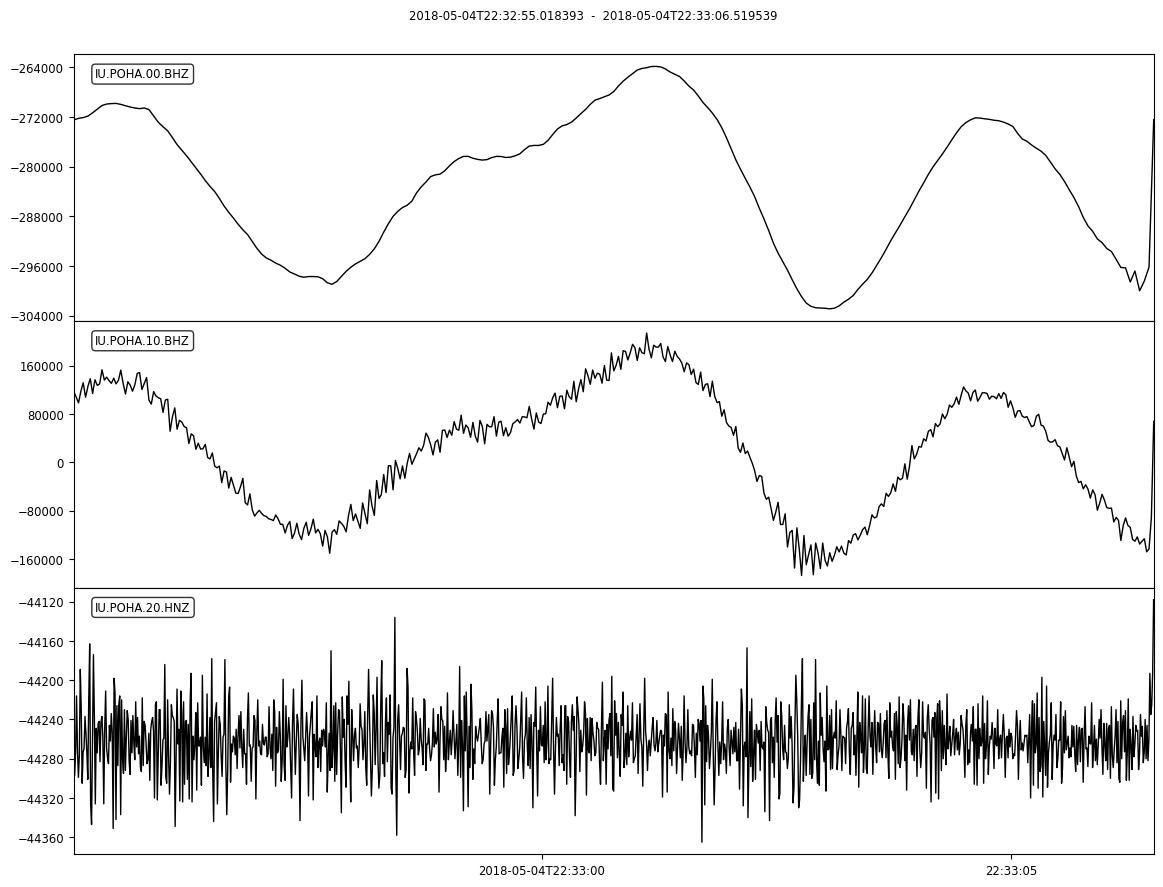

In [3]:
# Ruido Ambiental
from obspy import UTCDateTime

t_i = UTCDateTime("2018-05-04T22:32:55")
t_f = t_i + 11.5  # Antes de la onda P, tiempo escogido después de probar con 13s, 12,5s, 12s y 11,6s

st_ra = st.slice(starttime=t_i, endtime=t_f)


out1 = st_ra.plot(equal_scale=False, size=(1200, 900), number_of_ticks=5, show_y_UTC_label=True)
out1.savefig("ruidoambiental_tarea1.png", dpi=600)

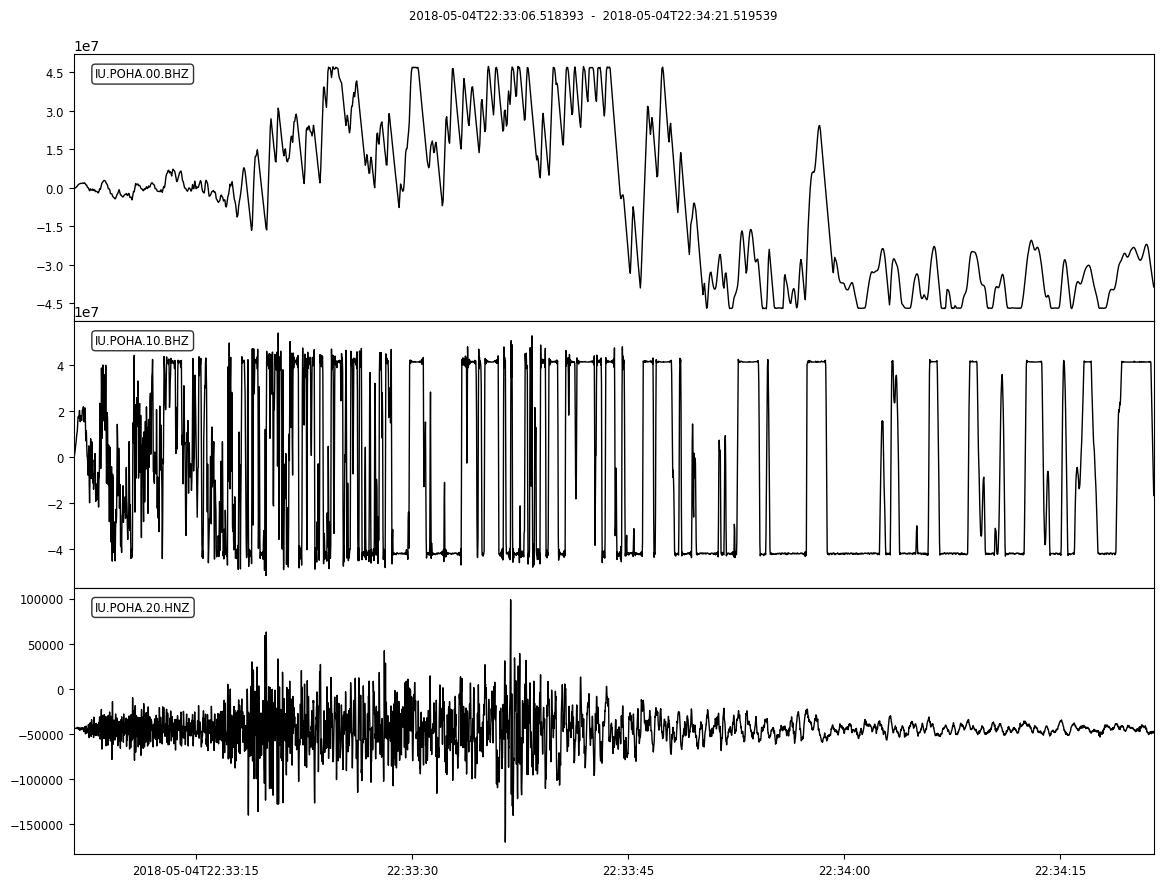

In [4]:
# Señal principal
from obspy import UTCDateTime

t_i = UTCDateTime("2018-05-04T22:32:55") + 11.5
t_f = t_i + 75  # Llegada de la onda P + 75 segundos, evento principal antes del 1er aftershock

st_sp = st.slice(starttime=t_i, endtime=t_f)


out1 = st_sp.plot(equal_scale=False, size=(1200, 900), number_of_ticks=5, show_y_UTC_label=True)
out1.savefig("señalprincipal_tarea1.png", dpi=600)

**Para la creación del código de este apartado se usó mucha más IA que en el resto del trabajo**

IU.POHA.00.BHZ | SNR Potencia: 4249255.6 | SNR (dB): 66.3 dB
IU.POHA.10.BHZ | SNR Potencia: 137979.9 | SNR (dB): 51.4 dB
IU.POHA.20.HNZ | SNR Potencia: 395998.3 | SNR (dB): 56.0 dB


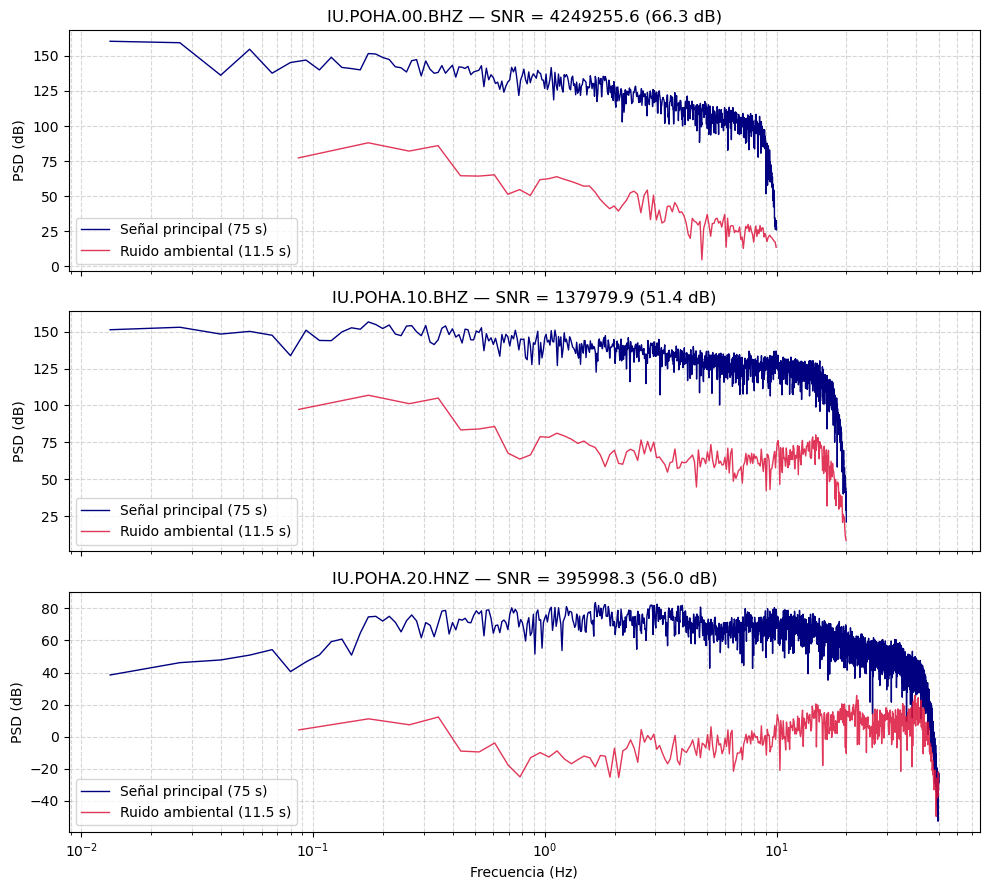

In [ ]:
# Estimación relación señal-ruido
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for i in range (0,3):
    tr_ra = st_ra[i].copy().detrend("demean").detrend("linear").taper(max_percentage=0.05, type="cosine")
    tr_sp = st_sp[i].copy().detrend("demean").detrend("linear").taper(max_percentage=0.05, type="cosine")

    def calcular_psd(tr): # Función creada a partir de lo último visto en ADS_P_04.ipynb + IA
        data = tr.data
        N = tr.stats.npts
        dt = tr.stats.delta
        Sr = tr.stats.sampling_rate

        fft_vals = np.fft.rfft(data)
        freqs = np.fft.rfftfreq(N,dt)
        psd = (np.abs(fft_vals) ** 2) / (N * Sr)
        psd[1:-1] *= 2 # Se multiplica por 2 ya que con la parte real solo tenemos la mitad
        return freqs, psd

    f_ra, psd_ra = calcular_psd(tr_ra)
    f_sp, psd_sp = calcular_psd(tr_sp)

    P_ra = np.trapezoid(psd_ra, f_ra)
    P_sp = np.trapezoid(psd_sp, f_sp)

    SNR_P = P_sp / P_ra
    SNR_db = 10 * np.log10(SNR_P)
    print(f"{tr_sp.id} | SNR Potencia: {SNR_P:.1f} | SNR (dB): {SNR_db:.1f} dB")

    ax = axes[i]
    ax.semilogx(
        f_sp[1:],
        10 * np.log10(psd_sp[1:]),
        color = "navy",
        lw = 1.0,
        label = "Señal principal (75 s)"
    )
    ax.semilogx(
        f_ra[1:],
        10 * np.log10(psd_ra[1:]),
        color = "crimson",
        lw = 1.0,
        alpha = 0.85,
        label = "Ruido ambiental (11.5 s)"
    )
    ax.set_ylabel("PSD (dB)")
    ax.set_title(f"{tr_sp.id} — SNR = {SNR_P:.1f} ({SNR_db:.1f} dB)")
    ax.grid(True, which = "both", ls = "--", alpha = 0.5)
    ax.legend(loc = "lower left")

axes[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout()
plt.savefig("SNR_psd_tarea1", dpi = 600, bbox_inches = "tight")
plt.show()


****

(f) Comment on the waveforms of the channels 00 and 10 and speculate on the reasons for any observable
differences.

**Comentar**

****

*(g) Explain the differences between the waveforms recorded by the seismometers and the accelerometer
and the peak accelerations recorded. Which instrument is more useful for recording this event?*

**Explicar**